Contexto del Negocio Ustedes son los Ingenieros de Datos de una alianza global de aerolíneas. Les han entregado el archivo vuelos_10k.csv extraído directamente de los servidores antiguos de la torre de control. Su objetivo final es modelar la red de rutas aéreas utilizando Teoría de Grafos (networkx), pero el sistema advierte que el archivo está lleno de errores de captura.

🧹 Fase 1: Limpieza Estructural (Data Cleaning)
Antes de construir el grafo, deben usar pandas y las técnicas que vimos en la Unidad I y II para purificar la tabla.

Valores Nulos: Encuentren y eliminen cualquier registro que no tenga Origen o Destino.
Formato Inconsistente: El código del aeropuerto siempre debe ser de 3 letras mayúsculas (Ej. "MEX"). Arreglen las filas que estén en minúsculas.
Anomalías Lógicas (Self-Loops): Un avión no puede despegar de un aeropuerto y aterrizar en ese mismo aeropuerto. ¿Qué debemos hacer con esos registros?
Errores de Captura: La distancia no puede ser un número negativo, corrijan esos errores.
Duplicados: Para modelar la red, solo necesitamos saber si existe la ruta. Eliminen las filas duplicadas (mismo origen y mismo destino).


🕸️ Fase 2: Extracción de la Red
Con su DataFrame perfectamente limpio (que actúa como una Lista de Aristas o Edge List):

Importen la librería networkx.
Utilicen la función nx.from_pandas_edgelist() para convertir su DataFrame en un Grafo Dirigido (nx.DiGraph).
Impriman en pantalla cuántos Nodos (Aeropuertos) y cuántas Aristas (Rutas) tiene su grafo final.


💥 Fase 3: El Experimento de la Memoria RAM
¡Llegó la hora de comprobar la teoría de la clase!

Construyan la Matriz de Adyacencia densa a partir de su grafo usando nx.adjacency_matrix(G).todense().
Utilicen código Python (ej. el atributo .nbytes) para calcular cuántos Megabytes (MB) de Memoria RAM está consumiendo su Matriz de Adyacencia llena de ceros.
Calculen cuántos Megabytes está consumiendo su DataFrame limpio (la Lista de Aristas).
Veredicto: Añadan una celda Markdown al final de su notebook respondiendo: ¿Cuántas veces más pesada es la Matriz en comparación con la Lista de Aristas y por qué sucede esto?

In [8]:
#Fase 1
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv('vuelos_10k.csv')
df.dropna(subset=['Origen', 'Destino'], inplace=True)
df['Origen'] = df['Origen'].str.strip().str.upper()
df['Destino'] = df['Destino'].str.strip().str.upper()

df = df[df['Origen'] != df['Destino']]

df['Distancia_km'] = df['Distancia_km'].abs()

df = df.drop_duplicates(subset=['Origen', 'Destino'], keep='first',)
print(df.head())


  Origen Destino  Distancia_km
0    RYI     KXK        965.34
1    ULE     PVC       1098.58
2    LTV     MOV       2713.63
3    NFR     CLR       1138.99
4    TSF     CZE       1691.08


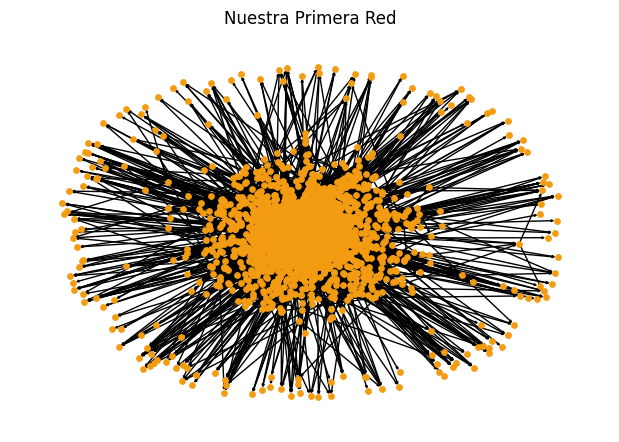

Número de Nodos (Aeropuertos): 3253
Número de Aristas (Rutas): 9743


In [ ]:
#Fase 2

G = nx.from_pandas_edgelist(df, source='Origen', target='Destino', edge_attr='Distancia_km', create_using=nx.DiGraph())

plt.figure(figsize=(6,4))
nx.draw(G, with_labels=False, node_color='#F39C12', node_size=15, arrowsize=3)
plt.title('Nuestra Primera Red')
plt.show()
#le quite los labels para que no se vea tan horrible

print(f"Número de Nodos (Aeropuertos): {G.number_of_nodes()}")
print(f"Número de Aristas (Rutas): {G.number_of_edges()}")

In [ ]:
# Fase 3

matriz_densa = nx.adjacency_matrix(G).todense()

mb_matriz = matriz_densa.nbytes / (1024 * 1024)
print(f"Memoria RAM de la Matriz de Adyacencia: {mb_matriz:.2f} MB")

mb_df = df.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"Memoria RAM del DataFrame: {mb_df:.2f} MB")

proporcion = mb_matriz / mb_df
print(f"La matriz es {proporcion:.2f} veces más pesada.")

Memoria RAM de la Matriz de Adyacencia: 80.73 MB
Memoria RAM del DataFrame: 1.26 MB
La matriz es 63.89 veces más pesada.


¿Cuántas veces más pesada es la Matriz en comparación con la Lista de Aristas y por qué sucede esto?
La matriz es 63.89 veces mas pesada, esto es debido a que reserva espacio dentro de la memoria para los vuelos, y los vuelos inexistentes, si no hay vuelos de x a y en vez de omitirlo o ignorarlo, le pone un 0, y asi por miles o incluso millones de datos.